FOUNDING DATE DISTRIBUTION PLOTS

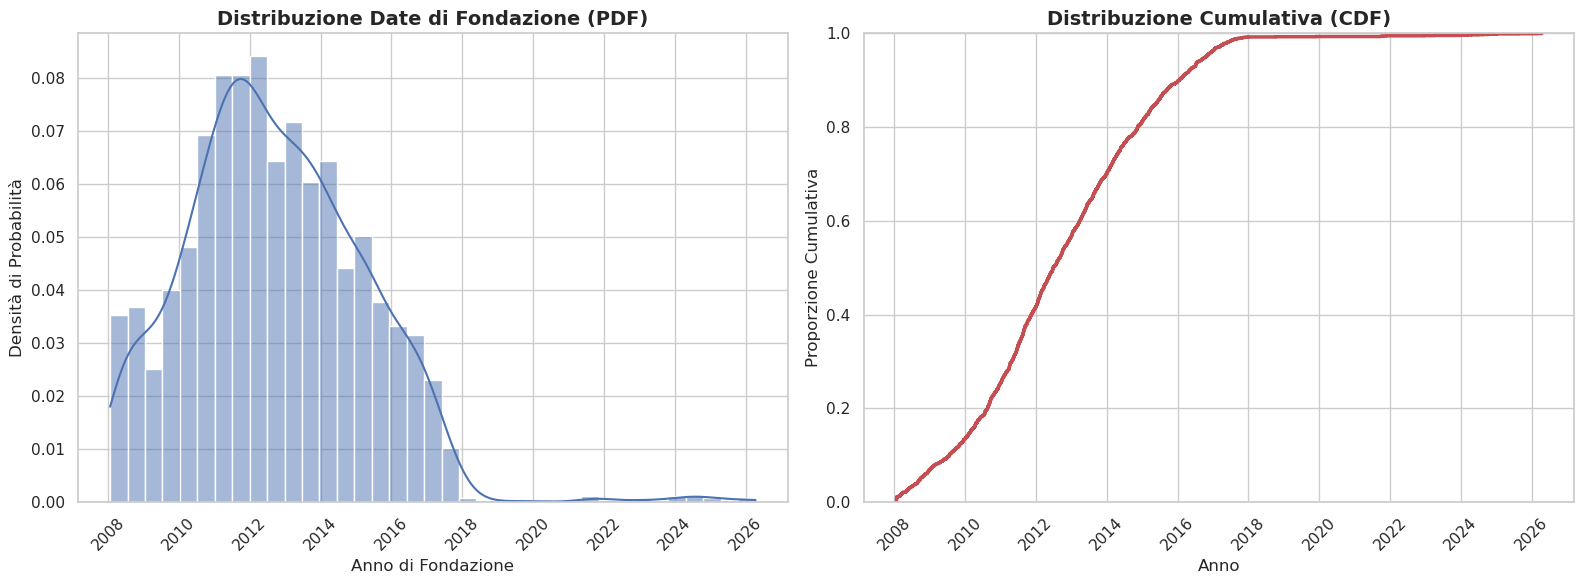

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

file_path = "data/interim/foundersData.csv"
df = pd.read_csv(file_path, index_col=0)

df['subreddit_creation_date'] = pd.to_datetime(df['subreddit_creation_date'], unit='s')

sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Probability Density Function

sns.histplot(data=df, x='subreddit_creation_date', kde=True, stat="probability", ax=axes[0], color="#4C72B0")
axes[0].set_title('Distribuzione Date di Fondazione (PDF)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Anno di Fondazione', fontsize=12)
axes[0].set_ylabel('Densità di Probabilità', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# Cumulative Distribution Function

sns.ecdfplot(data=df, x='subreddit_creation_date', ax=axes[1], color="#C44E52", lw=2.5)
axes[1].set_title('Distribuzione Cumulativa (CDF)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Anno', fontsize=12)
axes[1].set_ylabel('Proporzione Cumulativa', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

LATENCY DISTRIBUTION PLOTS (DAYS BETWEEN FIRST POST AND SUBREDDIT CREATION DATE)

Subreddits with Negative Latency (corrupted data): 4
Subreddits with above a Week of Latency: 781
Subreddits with above a Month of Latency: 598
Subreddits with above 100 Days of Latency: 418
Subreddits with above 500 Days of Latency: 104
Subreddits with above 1000 Days of Latency: 29
Subreddits with above 1500 Days of Latency: 9
Subreddits with above 2000 Days of Latency: 6


Latency Days Data
count    2829.000000
mean       63.048333
std       215.501139
min     -4006.706563
25%         0.002627
50%         0.025069
75%        13.267743
max      2486.030498
Name: latency_days, dtype: float64




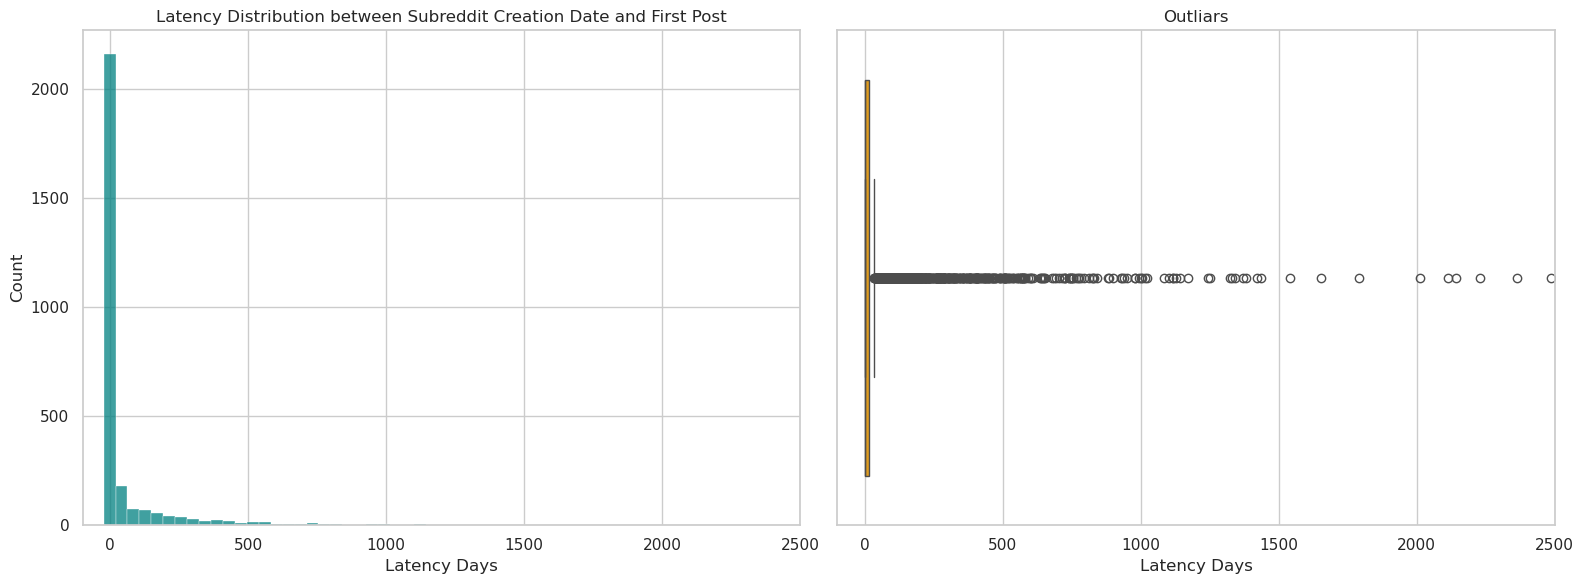

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

founders_data_path = "data/interim/conspiracy_founders_clean.csv"
founders_features_path = "data/interim/founders_features_clean.csv"

founders_data = pd.read_csv(founders_data_path, index_col=0)
founders_features = pd.read_csv(founders_features_path, index_col=0)



founders_data["post_creation_date"] = pd.to_datetime(founders_data["post_creation_date"], unit='s')
founders_data["subreddit_creation_date"] = pd.to_datetime(founders_data["subreddit_creation_date"], unit='s')
founders_features["active since"] = pd.to_datetime(founders_features["active since"], unit='s')

df = pd.merge(founders_data, founders_features, how="inner", on="username")
df.rename(columns={"subreddit_name" : "subredditName"}, inplace=True)

# check latency between subreddit creation and first post
df["latency_days"] = (df["post_creation_date"] - df["subreddit_creation_date"]).dt.total_seconds() / 86400
negative_latency_rows, _ = df[ df["latency_days"] < 0 ].shape
print(f"Subreddits with Negative Latency (corrupted data): {negative_latency_rows}")

# check number of outliars
above_7_latency, _ = df[ df["latency_days"] >= 7 ].shape
above_30_latency, _ = df[ df["latency_days"] >= 30 ].shape
above_100_latency, _ = df[ df["latency_days"] >= 100 ].shape
above_500_latency, _ = df[ df["latency_days"] >= 500 ].shape
above_1000_latency, _ = df[ df["latency_days"] >= 1000 ].shape
above_1500_latency, _ = df[ df["latency_days"] >= 1500 ].shape
above_2000_latency, _ = df[ df["latency_days"] >= 2000 ].shape
print(f"Subreddits with above a Week of Latency: {above_7_latency}\nSubreddits with above a Month of Latency: {above_30_latency}\nSubreddits with above 100 Days of Latency: {above_100_latency}\nSubreddits with above 500 Days of Latency: {above_500_latency}\nSubreddits with above 1000 Days of Latency: {above_1000_latency}\nSubreddits with above 1500 Days of Latency: {above_1500_latency}\nSubreddits with above 2000 Days of Latency: {above_2000_latency}\n\n")
print(f"Latency Days Data\n{df["latency_days"].describe()}\n\n")

# GRAPHS
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(data=df, x="latency_days", ax=axes[0], color="teal", bins=150)
sns.boxplot(data=df, x="latency_days", ax=axes[1], color="orange")

axes[0].set_title("Latency Distribution between Subreddit Creation Date and First Post")
axes[0].set_xlabel("Latency Days")
axes[1].set_title("Outliars")
axes[1].set_xlabel("Latency Days")
axes[1].set_ylabel("")

axes[0].set_xlim(-100,2500)
axes[1].set_xlim(-100, 2500)

plt.tight_layout()
plt.show()

FOUNDERS SENIORITY PLOT

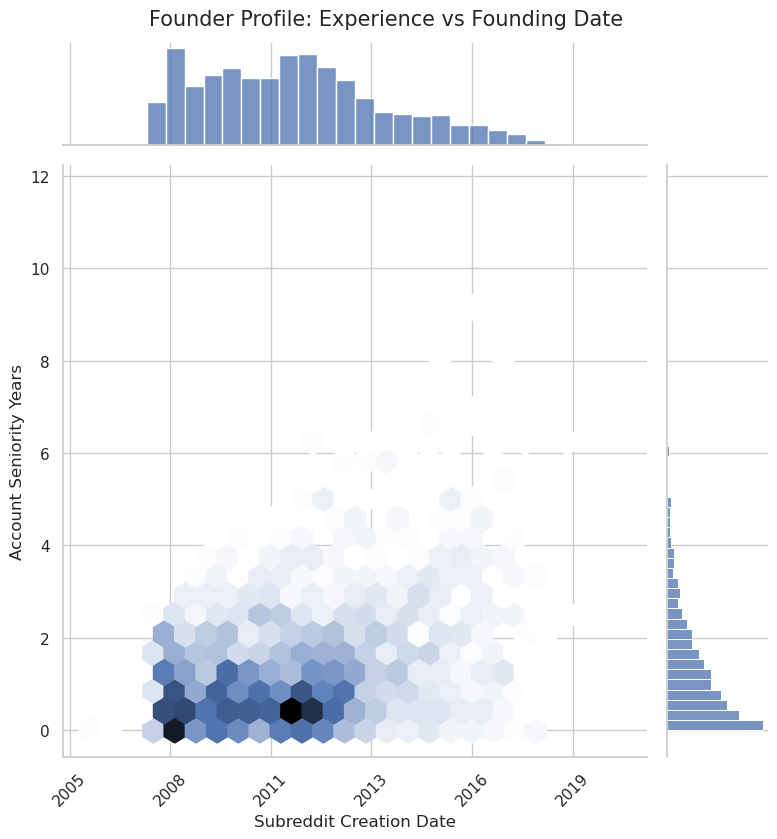

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

founders_data_path = "data/interim/conspiracy_founders_clean.csv"
founders_features_path = "data/interim/founders_features_clean.csv"

founders_data = pd.read_csv(founders_data_path, index_col=0)
founders_features = pd.read_csv(founders_features_path, index_col=0)

founders_data["post_creation_date"] = pd.to_datetime(founders_data["post_creation_date"], unit='s')
founders_data["subreddit_creation_date"] = pd.to_datetime(founders_data["subreddit_creation_date"], unit='s')
founders_features["active since"] = pd.to_datetime(founders_features["active since"], unit='s')

df = pd.merge(founders_data, founders_features, how="inner", on="username")
df.rename(columns={"name" : "subredditName"}, inplace=True)


df["account_seniority_years"] = (df["subreddit_creation_date"] - df["active since"]).dt.total_seconds() / (86400 * 365)
df_insight = df[df["account_seniority_years"] >= 0].copy()

df_insight['date_numeric'] = mdates.date2num(df_insight['subreddit_creation_date'])

g = sns.jointplot(
    data=df_insight, 
    x="date_numeric", 
    y="account_seniority_years",
    kind="hex", 
    color="#4C72B0",
    height=8,
    gridsize=25,
    joint_kws={"mincnt":1}
)

g.ax_joint.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(g.ax_joint.get_xticklabels(), rotation=45)

g.fig.suptitle("Founder Profile: Experience vs Founding Date", y=1.02, fontsize=15)
g.set_axis_labels("Subreddit Creation Date", "Account Seniority Years", fontsize=12)

plt.show()

MATCHING FEATURES DISTRIBUTION PLOTS

count    2232.000000
mean      280.743728
std       256.051553
min         2.000000
25%       102.000000
50%       210.500000
75%       375.500000
max      2776.000000
Name: num subreddits, dtype: float64


count      2232.000000
mean       8850.986559
std       13637.184244
min           3.000000
25%        1398.750000
50%        4104.000000
75%       10044.500000
max      130833.000000
Name: num contributions, dtype: float64




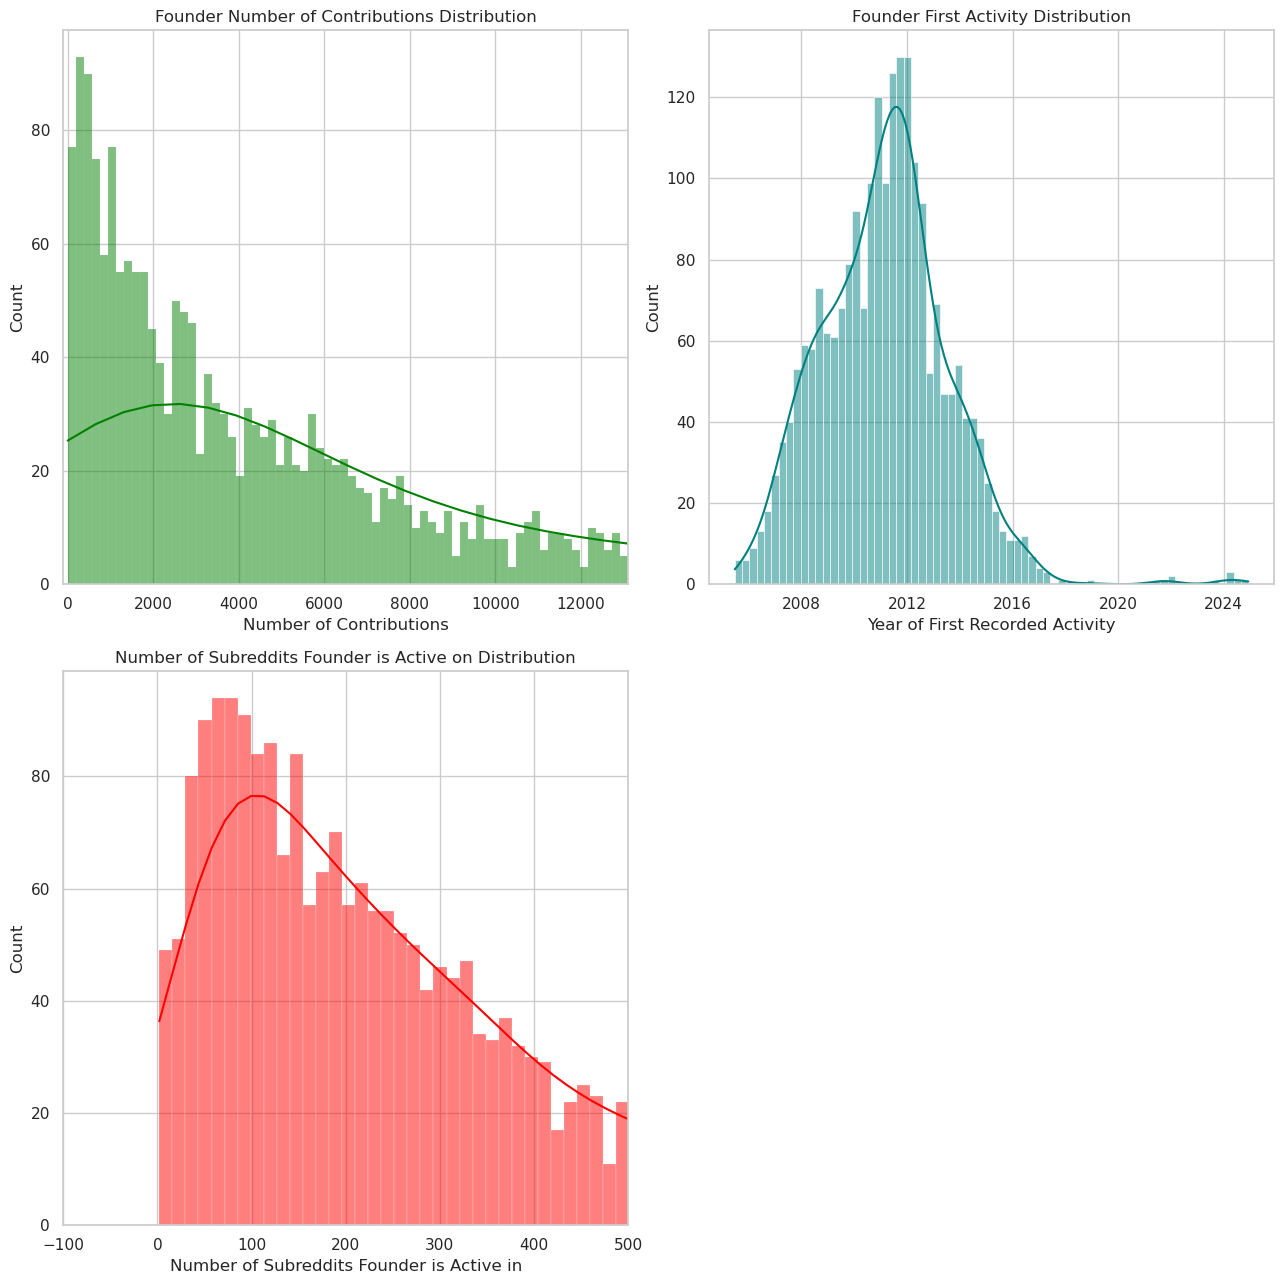

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

df = pd.read_csv("data/interim/realFounders_features_clean.csv", index_col=0)
df["active since"] = pd.to_datetime(df["active since"], unit='s')
df["subreddits"] = df["subreddits"].apply(ast.literal_eval)
df["num subreddits"] = df["subreddits"].apply(len)
print(df["num subreddits"].describe())
print("\n")
print(df["num contributions"].describe())
print("\n")

fig, axes = plt.subplots(2, 2, figsize=(13,13))
axes[1, 1].set_visible(False)
sns.histplot(data=df, x="num contributions", kde=True, ax=axes[0][0], bins=700, color="green")
sns.histplot(data=df, x="active since", kde=True, ax=axes[0][1], bins=70, color="teal")
sns.histplot(data=df, x="num subreddits", kde=True, ax=axes[1][0], bins=200, color="red")

axes[0][0].set_xlim(-100,13100)
axes[1][0].set_xlim(-100,500)

axes[0][0].set_title("Founder Number of Contributions Distribution")
axes[0][0].set_xlabel("Number of Contributions")
axes[0][1].set_title("Founder First Activity Distribution")
axes[0][1].set_xlabel("Year of First Recorded Activity")
axes[1][0].set_title("Number of Subreddits Founder is Active on Distribution")
axes[1][0].set_xlabel("Number of Subreddits Founder is Active in")

plt.tight_layout()
plt.show()